(graph_construction_guide)=

# Build a neighborhood graph stage by stage

A cell graph records which cells resemble one another: each node is a cell, and each edge is a weighted connection to one of its `k` nearest neighbors. CyteArc measures similarity in a reduced space, PCA for RNA, TF-IDF and LSI for ATAC, because lower dimensionality limits noisy features and keeps neighbor search efficient. Clustering, embeddings, imputation, and trajectory methods all utilize this graph.

CyteArc builds it in reusable stages: normalize the selected genes, reduce them, build an
approximate neighbor index, query `k` neighbors per cell, and convert distances into weighted connectivity. Executing the steps directly lets you change one parameter, insert batch correction, or {term}`reuse` an expensive reduction. Proximity in the chosen space does not by itself establish a shared cell identity; batch effects and other unwanted variation can also bring cells together.

Before you begin this page, start with [](scrna_seq.ipynb); this begins from an existing feature selection (see [](feature_selection.ipynb)), then builds an RNA graph stage by stage, checks it with graph diagnostics, and uses it for a layout and clustering. A separate initialization supplies starting coordinates for UMAP and t-SNE; it does not define graph edges.


`ds.pipeline.run()` orchestrates the standard RNA path and can continue through UMAP, clustering, doublet scoring, and markers.
Use it when the defaults match the analysis.
The stage methods below expose the same persisted results with more control.

## Build an RNA graph explicitly

The rebuilt store carries a completed `docs_default` pipeline run. This page starts from that
run's frozen cell and feature selections, then calls every graph stage explicitly. Identical calls
reuse the run's matching artifacts, as normalization and PCA do here. An earlier CyteArc release
built the run's neighbor index with other defaults (`ann_m=48`, `ann_efc=50`, and `ann_ef=50`,
against the current 24, 200, and 200), so `graph.ann_index` builds a new index, and the
neighbors, graph, UMAP, and clusters below are new results rather than the run's. Later sections
create the branches they discuss.

In [1]:
# Arrange and save Matplotlib figures.
import matplotlib.pyplot as plt

# Work with numeric arrays and cell masks.
import numpy as np

# Summarize cells and results in tables.
import pandas as pd

# Open count stores and run CyteArc analyses.
import cytearc

# Use CyteArc plotting options and diagnostics.
import cytearc.plotting as splt

# Keep routine logs and progress bars out of the results.
cytearc.configure_output(level="WARNING", progress=False)

# Download the prepared example store.
dataset = cytearc.cytebase.connect("cytearc_docs").download_dataset(
    "tenx_5K_pbmc_rnaseq",
    destination="cytearc_datasets",
    zarr=True,
)

# Open the count store for this analysis.
ds = cytearc.DataStore(f"{dataset}/data.zarr", nthreads=4)

# Open the saved analysis that supplies the starting selections.
baseline = ds.pipeline.open(label="docs_default")

# Inspect the opened store's cells and features.
ds

DataStore has 3948 (5025) cells with 1 assays: RNA
   Cell metadata:
            'I', 'ids', 'names', 'RNA_G2M_score', 'RNA_S_score', 
            'RNA_UMAP1', 'RNA_UMAP2', 'RNA_cell_cycle_phase', 'RNA_clusters', 'RNA_doublet_score', 
            'RNA_leiden_cluster', 'RNA_nCounts', 'RNA_nFeatures', 'RNA_paris_cluster', 'RNA_percentMito', 
            'RNA_percentRibo'
   RNA assay has 33538 features and following metadata:
            'I', 'ids', 'names', 'dropOuts', 'feature_type', 
            'genome', 'nCells'

Started: 2026-10-23T14:34:28.128439Z | Wall time: 7.808 s

Retrieve the cell and gene selections used by the saved analysis:

In [2]:
# Keep the cells used by the saved analysis.
cell_selection = baseline["analysis_cell_selection"]

# Keep the variable genes used by the saved analysis.
hvg_ref = baseline["highly_variable_features"]

# Use the cell metadata frozen with this analysis.
run_cells = baseline.cells

# Inspect the saved cell and gene selections.
{"cells": cell_selection, "genes": hvg_ref}

{'cells': ArtifactRef(datastore, kind='cell_selection', artifact_id='9a63ee79046c...'),
 'genes': ArtifactRef(assay='RNA', kind='feature_selection', artifact_id='b7264ef081bc...')}

Started: 2026-10-23T14:34:35.939326Z | Wall time: 0.126 s

Each method returns a reference to its saved result. Pass it to the next method to keep the
steps connected. We use 15 PCs to match the prepared example; `reduction.pca` defaults to 21.

In [3]:
# Normalize counts over the selected features.
normalized = ds.features.normalize(cell_selection, hvg_ref)

# Reduce the normalized expression to principal components.
pca = ds.reduction.pca(normalized, dims=15)

# Inspect the PCA result that will supply neighbor coordinates.
pca

ArtifactRef(assay='RNA', kind='reduction', artifact_id='c9b9750ea449...')

Started: 2026-10-23T14:34:36.067304Z | Wall time: 0.176 s

Build the neighbor index from PCA, then turn neighbor distances into connectivity:

In [4]:
# Build the nearest-neighbor search index from the reduction.
ann_index = ds.graph.ann_index(pca)

# Find neighbors of each cell in the reduced space.
neighbors = ds.graph.neighbors(ann_index)

# Convert neighbor distances into weighted connectivity.
graph = ds.graph.connectivity(neighbors)

# Inspect the saved connectivity graph.
graph

ArtifactRef(assay='RNA', kind='connectivity_map', artifact_id='36045e707503...')

Started: 2026-10-23T14:34:36.245432Z | Wall time: 22.130 s

The default neighbour count is 11. We will change only that value in the comparison below.

`graph.load` returns a sparse cell-by-cell connectivity matrix. Its default keeps the directed
neighbour edges. For the diagnostics below, use `symmetric=True` to include a connection when
either cell selects the other. This lets us count each cell's neighbours in either direction.
A cell can then have more than `k` neighbours because other cells may select it. In this symmetric
matrix, `nnz` counts both directions of each connection.

In [5]:
# Load a symmetric sparse graph for diagnostics.
loaded_graph = ds.graph.load(graph, symmetric=True)

# Check the number of cells and nonzero graph edges.
loaded_graph.shape, loaded_graph.nnz

((3948, 3948), 64858)

Started: 2026-10-23T14:34:58.381192Z | Wall time: 0.097 s

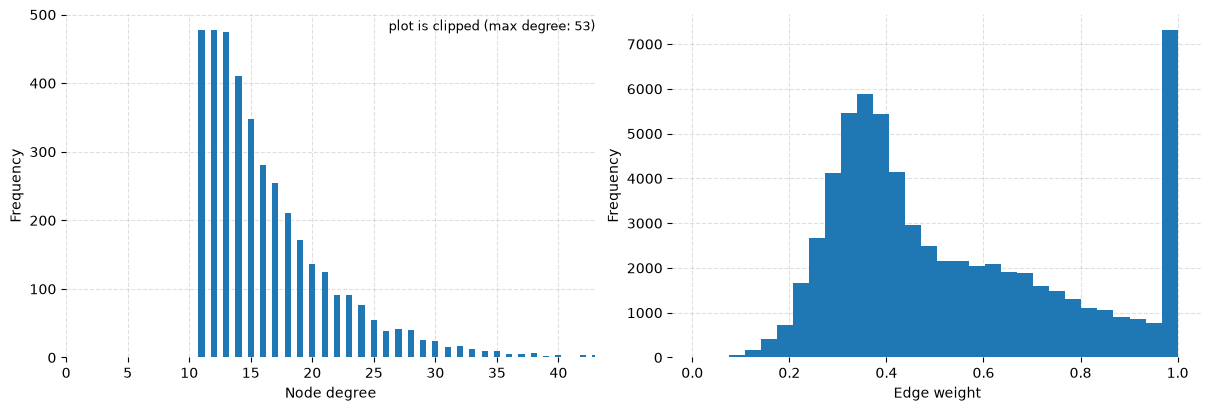

Started: 2026-10-23T14:34:58.480415Z | Wall time: 0.407 s

In [6]:
# Inspect graph degree and edge-weight distributions.
splt.graph_qc(loaded_graph)

Check isolation and whether degree tracks QC metrics before treating the graph as ready for clustering:

In [7]:
# Count the neighbors connected to each cell.
degrees = np.asarray((loaded_graph != 0).sum(axis=0)).ravel()

# Summarize graph coverage and isolated cells.
pd.Series(
    {
        "active cells": int(loaded_graph.shape[0]),
        "isolated cells": int((degrees == 0).sum()),
        "median degree": float(np.median(degrees)),
        "min degree": int(degrees.min()),
        "max degree": int(degrees.max()),
    },
    name="graph coverage",
)

active cells      3948.0
isolated cells       0.0
median degree       15.0
min degree          11.0
max degree          53.0
Name: graph coverage, dtype: float64

Started: 2026-10-23T14:34:58.890062Z | Wall time: 0.010 s

In [8]:
# Align graph degrees with the same cells' quality measurements.
degree_vs_qc = pd.DataFrame(
    {
        "degree": degrees,
        "RNA_nCounts": run_cells.fetch("RNA_nCounts"),
        "RNA_nFeatures": run_cells.fetch("RNA_nFeatures"),
    }
)

# Check whether graph degree tracks the quality measurements.
degree_vs_qc.corr(numeric_only=True)

,degree,RNA_nCounts,RNA_nFeatures
degree,1.000000,0.080260,0.017607
RNA_nCounts,0.080260,1.000000,0.877195
RNA_nFeatures,0.017607,0.877195,1.000000


Started: 2026-10-23T14:34:58.903501Z | Wall time: 0.045 s

The graph should contain a row for every selected cell, with finite positive weights on its
stored connections. Zero entries mean there is no edge between those cells. The degree summary
detects isolated cells, but a graph with no isolated cells can still contain separate components.

Separate components can represent distinct populations. Investigate unexpected fragmentation
or a strong relationship between degree and QC metrics using markers, feature selection, PCA
dimensions, and `k`. Increasing `k` just to join every component can connect unrelated cells.

## Use the graph for a layout and clustering

`embeddings.umap` and `embeddings.tsne` require both the graph and its matching initialization.
Leiden and Paris require the graph.
Each returns an immutable artifact without adding cell-metadata columns. Use
`clusters.load_paris(ref)` only when hierarchy diagnostics are needed.
Resolution 0.5 matches the prepared PBMC analysis; Leiden's default is 1.0.

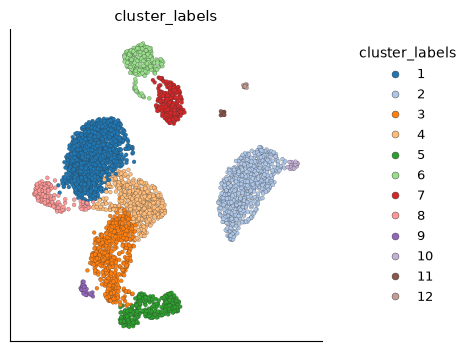

Started: 2026-10-23T14:34:58.951605Z | Wall time: 41.324 s

In [9]:
# Build starting coordinates for the embedding.
initialization = ds.embeddings.initialization(pca)

# Calculate the UMAP coordinates from the graph.
umap = ds.embeddings.umap(graph, initialization)

# Find groups of cells in the graph.
clusters = ds.clusters.leiden(graph, resolution=0.5)

# Read cluster labels in the selected cells' order.
cluster_values = np.asarray(ds.artifacts.load(clusters)["values"][:])

# Color the graph-derived UMAP by its Leiden clusters.
ds.plots.embedding(layout=umap, color_by=clusters)

## Branch by retaining both references

Suppose PCA and the approximate nearest-neighbor (ANN) index are expensive to recompute, but
you want to compare two neighbor counts. Query the same index with a different `k`: only the
neighbor and connectivity stages need new results. Keep both graph references so either analysis
can continue independently.

In [10]:
# Query the same index with 21 neighbors per cell.
neighbors_k21 = ds.graph.neighbors(ann_index, k=21)

# Build connectivity for the 21-neighbor comparison.
graph_k21 = ds.graph.connectivity(neighbors_k21)

# Check that the changed parameters produced a distinct result.
graph_k21 != graph

True

Started: 2026-10-23T14:35:40.278869Z | Wall time: 0.381 s

Both branches remain complete, addressable artifacts.
Downstream calls must receive one of them explicitly, so a parameter experiment cannot silently replace another branch.

Degree and edge weight both shift when every cell sees more neighbours:

In [11]:
# Load the comparison graph with symmetric edges.
loaded_graph_k21 = ds.graph.load(graph_k21, symmetric=True)

# Compare the number of stored edges in the two graphs.
pd.Series(
    {
        "k=11 nnz": int(loaded_graph.nnz),
        "k=21 nnz": int(loaded_graph_k21.nnz),
    },
    name="edges",
)

k=11 nnz     64858
k=21 nnz    121876
Name: edges, dtype: int64

Started: 2026-10-23T14:35:40.662199Z | Wall time: 0.088 s

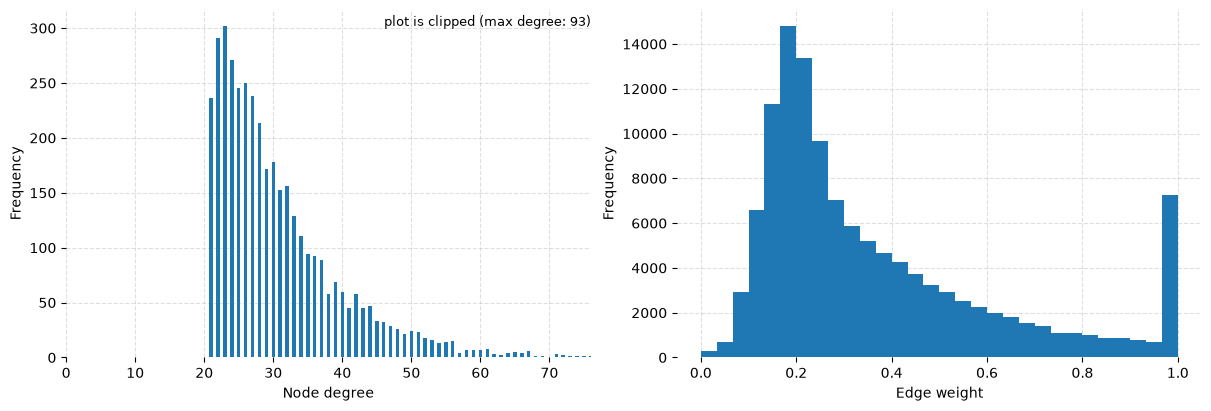

Started: 2026-10-23T14:35:40.753633Z | Wall time: 0.335 s

In [12]:
# Inspect graph degree and edge-weight distributions.
splt.graph_qc(loaded_graph_k21)

To analyse the side branch, pass its exact graph reference.
Retain both returned refs so neither branch replaces the other.

In [13]:
# Cluster the 21-neighbor graph at the same resolution.
clusters_k21 = ds.clusters.leiden(graph_k21, resolution=0.5)

# Read the comparison cluster labels.
cluster_values_k21 = np.asarray(ds.artifacts.load(clusters_k21)["values"][:])

# Count cells in each reported category.
pd.Series(cluster_values_k21, name="cluster").value_counts().sort_index()

cluster
1     1299
2      704
3      650
4      320
5      284
6      256
7      239
8      144
9       25
10      15
11      12
Name: count, dtype: int64

Started: 2026-10-23T14:35:41.090687Z | Wall time: 0.152 s

Place both partitions on the shared `k=11` UMAP so changes in group boundaries are visible,
then compare their assignments with a crosstab:

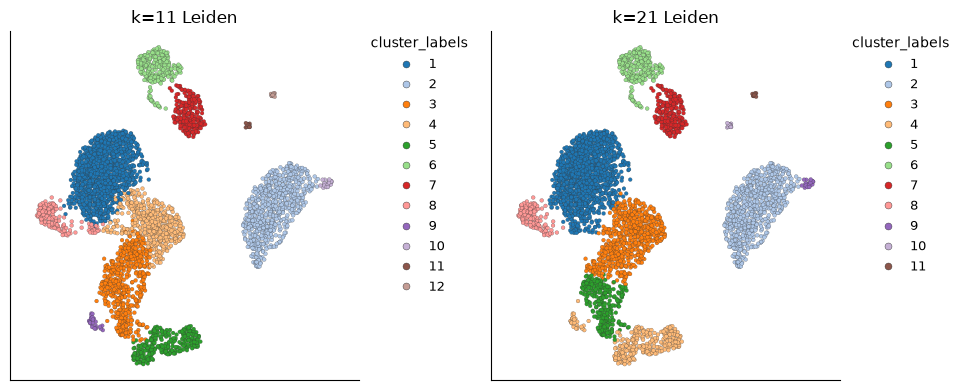

Started: 2026-10-23T14:35:41.245562Z | Wall time: 0.990 s

In [14]:
# Create axes for the comparison panels.
figure, axes = plt.subplots(1, 2, figsize=(10, 4))

# Draw each result on its comparison axes.
for axis, cluster_ref, title in zip(
    axes,
    (clusters, clusters_k21),
    ("k=11 Leiden", "k=21 Leiden"),
    strict=True,
):

    # Compare the two clusterings on the same k=11 UMAP.
    ds.plots.embedding(
        layout=umap,
        color_by=cluster_ref,
        target=axis,
        show_titles=False,
        show=False,
    )

    # Label the panel with the result it shows.
    axis.set_title(title)

# Adjust spacing between the comparison panels.
figure.tight_layout()

# Display the completed comparison figure.
figure

In [15]:
# Count cells shared by each pair of cluster assignments.
pd.crosstab(
    pd.Series(cluster_values, name="k=11"),
    pd.Series(cluster_values_k21, name="k=21"),
)

k=21,1,2,3,4,5,6,7,8,9,10,11
k=11,,,,,,,,,,,
1,1215,0,0,0,0,0,0,2,0,0,0
2,0,704,0,0,0,0,0,0,0,0,0
3,0,0,236,8,284,0,0,0,0,0,0
4,60,0,414,0,0,0,0,0,0,0,0
5,0,0,0,283,0,0,0,0,0,0,0
6,0,0,0,0,0,256,0,0,0,0,0
7,0,0,0,0,0,0,239,0,0,0,0
8,24,0,0,0,0,0,0,142,0,0,0
9,0,0,0,29,0,0,0,0,0,0,0


Started: 2026-10-23T14:35:42.237437Z | Wall time: 0.022 s

Cluster numbers can change even when the groups stay the same. Look for a row spread across
several columns, or a column collecting several rows, to find splits or merges that depend on
`k`. Review marker evidence before accepting those boundaries.

## Tune the neighbour search

The index defaults are `ann_m=24`, `ann_efc=200`, and `ann_ef=200`. `ann_m` controls
how many links the index can keep per node; increasing it uses more memory. `ann_efc`
controls the search effort while building that index; increasing it usually takes longer.
Changing either setting builds a new index.

`graph.neighbors(ann_ef=...)` changes only the query depth, so the existing index can
serve both a quick preview and a deeper search. By default, a query explores
`max(index ann_ef, 2 * k)` candidates. Explicit depths are at least `k + 1` to allow
for the cell itself. Here we compare a depth of 40 with the default depth of 200,
keeping `k=11` and the index fixed:


In [16]:
# Query the existing index with a smaller search depth for a preview.
preview_neighbors = ds.graph.neighbors(ann_index, k=11, ann_ef=40)

# Load the neighbours returned by the default search.
default_indices = np.asarray(ds.artifacts.load(neighbors)["indices"][:])

# Load the neighbours returned by the preview search.
preview_indices = np.asarray(ds.artifacts.load(preview_neighbors)["indices"][:])

# Calculate the mean fraction of neighbours shared by each cell.
shared_neighbors = np.mean(
    [
        np.isin(preview_row, default_row).mean()
        for preview_row, default_row in zip(
            preview_indices, default_indices, strict=True
        )
    ]
)

# Report each search's self-hit rate and agreement with the default search.
pd.DataFrame(
    {
        "search depth": [40, 200],
        "self-hit percent": [
            ds.artifacts.load(ref).attrs["self_hit_rate"]
            for ref in (preview_neighbors, neighbors)
        ],
        "neighbors shared with default": [shared_neighbors, 1.0],
    },
    index=["preview", "default"],
)


,search depth,self-hit percent,neighbors shared with default
preview,40,100.0,0.999931
default,200,100.0,1.000000


Started: 2026-10-23T14:35:42.262480Z | Wall time: 0.370 s

The preview returns 99.9931% of the neighbours found by the default search. Both self-hit
rates are 100%, so finding every cell itself does not guarantee the same neighbours at both
depths. This compares two approximate searches, not exact neighbour recall.

`self_hit_rate` is the percentage of cells found among their own candidate neighbours,
before self-edges are removed. Below 99.5%, CyteArc warns that other true neighbours may
also be missing. Try a larger query `ann_ef`, or rebuild with larger `ann_efc` or `ann_m`.
Identical coordinates can also lower this rate. The analysis above keeps the default graph.

## Recompute only what changed

Artifact identity includes the operation, scientific parameters, upstream inputs, and the operation's revision.
Calling an identical stage reuses its completed result.
Changing `k` reuses normalization, PCA, and the ANN index but creates new neighbour and connectivity artifacts.
Changing the cell or feature selection requires new downstream results. The saved results of
the earlier analysis remain available.

Harmony changes the coordinates used to measure similarity. It reuses the existing PCA result,
but its corrected coordinates need a new ANN index, neighbor search, and connectivity graph.
Use it only when the study design supports technical batch correction:


```python
# Correct PCA coordinates using a technical batch column.
corrected = ds.reduction.harmony(pca, ["technical_batch"])

# Build the neighbor index from corrected coordinates.
corrected_index = ds.graph.ann_index(corrected)

# Find neighbors in the corrected space.
corrected_neighbors = ds.graph.neighbors(corrected_index, k=21)

# Build connectivity from the corrected neighbors.
corrected_graph = ds.graph.connectivity(corrected_neighbors)
```

Use [](../concepts/provenance.md) to inspect complete lineage and [](reuse_and_tracing.ipynb) for reuse and invalidation patterns.